In [15]:
import os
import sys
import pandas as pd
import glob
import numpy as np
from scipy.signal import savgol_filter

from utils.plotting import plot_movement_data
from utils.plotting import plot_movement_data_3d


BASE_PATH = './ICater_Shoulder_Elbow_Hand/data/processed/LOF_DTW_Inliers'
# BASE_PATH = './data/raw/all_sensors'


In [16]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_csv = pd.read_csv('./data/raw/outliers/outliers.csv').drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()


--- Fusing Outliers into a singular Ground Truth ---
Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


### Read, Format and Fuse Left and Right Hand Data

In [17]:
csv_files = glob.glob(f'{BASE_PATH}/*.csv')


df = pd.concat([pd.read_csv(f, delimiter=",") for f in csv_files], ignore_index=True)

# Map movement types to labels
mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Move'} 
df['movLabel'] = df['movType'].map(mapa_mov)

# Add Jerk column
df["jerk"] = df.groupby(['sub', 'repID', 'movID'])['acc'].diff().fillna(0)

df.head()

,sub,repID,movID,movType,step,xs,ys,zs,xe,ye,ze,xw,yw,zw,vel,acc,t,k,movLabel,jerk
0,6,1,1,0,1,-19.416119,191.445720,1455.119161,-73.768601,205.853671,1143.174685,-187.534286,217.491546,910.599346,0.012873,0.021275,-0.172269,2.697837,Pick,0.000000
1,6,1,1,0,2,-19.508986,191.468112,1455.089650,-73.879769,205.854552,1143.146713,-187.742206,217.435138,910.603327,0.012939,0.039943,-0.465353,4.939217,Pick,0.018667
2,6,1,1,0,3,-19.554322,191.505035,1455.042424,-73.990135,205.936455,1143.112378,-187.957126,217.420031,910.602861,0.013292,0.074186,-1.444924,8.564583,Pick,0.034243
3,6,1,1,0,4,-19.558498,191.555501,1454.978893,-74.102149,206.089674,1143.072063,-188.185726,217.436719,910.601448,0.014188,0.103099,-3.299226,10.266306,Pick,0.028913
4,6,1,1,0,5,-19.527886,191.618522,1454.900466,-74.218261,206.304506,1143.026154,-188.434688,217.475693,910.602585,0.015738,0.125656,-6.755100,9.310180,Pick,0.022558


In [18]:
# Separar em 3 DataFrames independentes (usando .get() para não dar erro se faltar algum)
df_inliers_pick = df[df['movLabel'] == 'Pick']
df_inliers_place = df[df['movLabel'] == 'Place']
df_inliers_move = df[df['movLabel'] == 'Move']

--- Configuração do Gráfico para Pick ---
Linhas de Inliers (Trajetórias Normais): 30876
Linhas de Outliers Detetados (Vão aparecer a Vermelho): 0

--- A gerar gráfico 3D para a Mão DIREITA ---


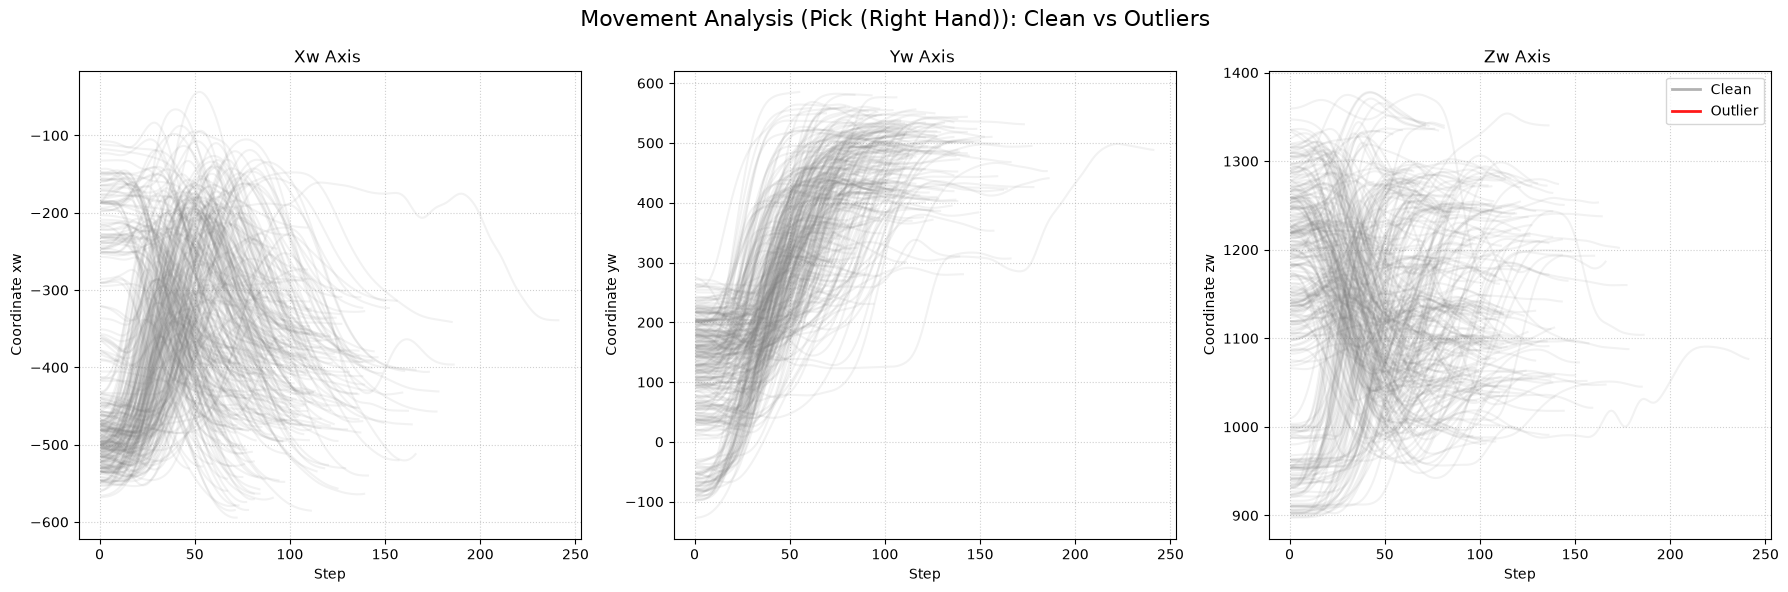

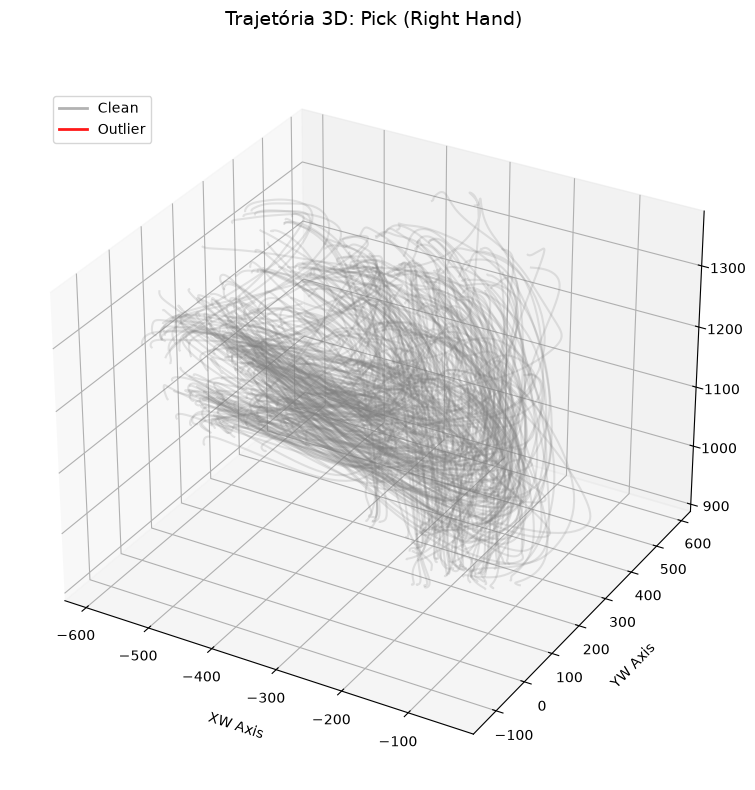

In [19]:
# ==========================================
# DIAGNÓSTICO E VISUALIZAÇÃO DE CONFIGURAÇÃO
# ==========================================

# 1. Escolhe o movimento que queres analisar neste gráfico

TARGET_MOV = 'Pick'  # Podes mudar para 'Place' ou 'Move'

# 2. Selecionar o DataFrame de inliers correto com base na tua escolha
if TARGET_MOV == 'Pick':
    inliers_temp = df_inliers_pick.copy()
elif TARGET_MOV == 'Move':
    inliers_temp = df_inliers_move.copy()
elif TARGET_MOV == 'Place':
    inliers_temp = df_inliers_place.copy()
else:
    inliers_temp = df_inliers_move.copy()

# Criar a chave 'temp_key' para agrupar as séries temporais nos inliers
inliers_temp['temp_key'] = inliers_temp['sub'].astype(str) + "_" + \
                           inliers_temp['repID'].astype(str) + "_" + \
                           inliers_temp['movID'].astype(str)

# 3. EXTRAIR OS OUTLIERS VERDADEIROS
# Vamos ao teu DataFrame original ('df' que carregou o filtered_data.csv completo)
df_original_mov = df[df['movLabel'] == TARGET_MOV].copy()

# Criar a mesma chave 'temp_key' no DataFrame original
df_original_mov['temp_key'] = df_original_mov['sub'].astype(str) + "_" + \
                              df_original_mov['repID'].astype(str) + "_" + \
                              df_original_mov['movID'].astype(str)

# Os outliers detetados são as linhas que estão no original mas NÃO estão nos inliers limpos
outliers_temp = df_original_mov[~df_original_mov['temp_key'].isin(inliers_temp['temp_key'])].copy()

print(f"--- Configuração do Gráfico para {TARGET_MOV} ---")
print(f"Linhas de Inliers (Trajetórias Normais): {len(inliers_temp)}")
print(f"Linhas de Outliers Detetados (Vão aparecer a Vermelho): {len(outliers_temp)}")


print("\n--- A gerar gráfico 3D para a Mão DIREITA ---")
plot_movement_data(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw', 'yw', 'zw']
)


plot_movement_data_3d(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw', 'yw', 'zw']
)

### Ver quais séries foram retiradas
Quero validar se eu descartei a série inteira (todos os movimentos "Pick", "Move" e "Place") se algum deles for considerado outlier

In [20]:
# Definir o que constitui uma repetição "perfeita" e completa
expected_movs = ['Pick', 'Move', 'Place']
num_expected_movs = len(expected_movs)

# Assumimos que o df_final é o teu dataset limpo (ex: df_gold_standard)
df_final = df # Substitui pelo nome do teu dataframe se for diferente

for sub in sorted(df_final['sub'].unique()):
    print(f"Start Analyzing Subject {sub}")
    
    # Isolar os dados do sujeito (Torna os loops internos muito mais rápidos)
    df_sub = df_final[df_final['sub'] == sub]
    
    last_repID = -1

    for repID in sorted(df_sub['repID'].unique()):
        
        # Isolar os dados desta repetição específica
        df_rep = df_sub[df_sub['repID'] == repID]
        
        # ====================================================================
        # 1. VALIDAÇÃO DE INTEGRIDADE (A Guilhotina falhou?)
        # ====================================================================
        movimentos_presentes = df_rep['movLabel'].unique()
        
        if len(movimentos_presentes) != num_expected_movs:
            print(f"  🚨 ALERTA CRÍTICO: Sujeito {sub}, RepID {repID} está corrompido/incompleto!")
            print(f"     -> Sobreviveram apenas os movimentos: {movimentos_presentes}")
            print(f"     -> A repetição não foi apagada por completo. Verifica a Guilhotina!")
        
        # ====================================================================
        # 2. VALIDAÇÃO DE SEQUÊNCIA (Saltos no repID)
        # ====================================================================
        if repID == 9:
            pass # A tua regra específica para ignorar o 9
        elif last_repID != -1 and repID != (last_repID + 1):
            print(f"  ⚠️ Aviso: Salto de repID no Sub {sub}. Esperava {last_repID + 1}, mas detetou {repID}.")
            
        last_repID = repID

Start Analyzing Subject 1
Start Analyzing Subject 2
  ⚠️ Aviso: Salto de repID no Sub 2. Esperava 2, mas detetou 3.
Start Analyzing Subject 3
Start Analyzing Subject 4
Start Analyzing Subject 5
Start Analyzing Subject 6
Start Analyzing Subject 7
Start Analyzing Subject 8
Start Analyzing Subject 9
Start Analyzing Subject 10
Start Analyzing Subject 11
Start Analyzing Subject 12
Start Analyzing Subject 13
  ⚠️ Aviso: Salto de repID no Sub 13. Esperava 3, mas detetou 4.
Start Analyzing Subject 14
Start Analyzing Subject 15
Start Analyzing Subject 16
Start Analyzing Subject 17
Start Analyzing Subject 18
Start Analyzing Subject 19
